In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

from scipy import stats

In [2]:
data = pd.read_csv("Diamonds Prices2022.csv", index_col=0)
data.head(10)

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
6,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
7,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
8,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
9,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
10,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


In [3]:
data.describe()

,carat,depth,table,price,x,y,z
count,53943.000000,53943.000000,53943.000000,53943.000000,53943.000000,53943.000000,53943.000000
mean,0.797935,61.749322,57.457251,3932.734294,5.731158,5.734526,3.538730
std,0.473999,1.432626,2.234549,3989.338447,1.121730,1.142103,0.705679
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.000000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53943 entries, 1 to 53943
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53943 non-null  float64
 1   cut      53943 non-null  object 
 2   color    53943 non-null  object 
 3   clarity  53943 non-null  object 
 4   depth    53943 non-null  float64
 5   table    53943 non-null  float64
 6   price    53943 non-null  int64  
 7   x        53943 non-null  float64
 8   y        53943 non-null  float64
 9   z        53943 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.5+ MB


In [5]:
data["volume"] = data["x"] * data["y"] * data["z"]
data.drop(columns=["x", "y", "z"], inplace=True)

data.head(10)

,carat,cut,color,clarity,depth,table,price,volume
1,0.23,Ideal,E,SI2,61.5,55.0,326,38.202030
2,0.21,Premium,E,SI1,59.8,61.0,326,34.505856
3,0.23,Good,E,VS1,56.9,65.0,327,38.076885
4,0.29,Premium,I,VS2,62.4,58.0,334,46.724580
5,0.31,Good,J,SI2,63.3,58.0,335,51.917250
6,0.24,Very Good,J,VVS2,62.8,57.0,336,38.693952
7,0.24,Very Good,I,VVS1,62.3,57.0,336,38.830870
8,0.26,Very Good,H,SI1,61.9,55.0,337,42.321081
9,0.22,Fair,E,VS2,65.1,61.0,337,36.425214
10,0.23,Very Good,H,VS1,59.4,61.0,338,38.718000


In [6]:
print(data["cut"].unique())
print(data["color"].unique())
print(data["clarity"].unique())

['Ideal' 'Premium' 'Good' 'Very Good' 'Fair']
['E' 'I' 'J' 'H' 'F' 'G' 'D']
['SI2' 'SI1' 'VS1' 'VS2' 'VVS2' 'VVS1' 'I1' 'IF']


In [7]:
data = pd.get_dummies(data, columns=["cut", "color", "clarity"], drop_first=True)
data.head(10)

,carat,depth,table,price,volume,cut_Good,cut_Ideal,cut_Premium,cut_Very Good,color_E,...,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
1,0.23,61.5,55.0,326,38.202030,False,True,False,False,True,...,False,False,False,False,False,True,False,False,False,False
2,0.21,59.8,61.0,326,34.505856,False,False,True,False,True,...,False,False,False,False,True,False,False,False,False,False
3,0.23,56.9,65.0,327,38.076885,True,False,False,False,True,...,False,False,False,False,False,False,True,False,False,False
4,0.29,62.4,58.0,334,46.724580,False,False,True,False,False,...,False,True,False,False,False,False,False,True,False,False
5,0.31,63.3,58.0,335,51.917250,True,False,False,False,False,...,False,False,True,False,False,True,False,False,False,False
6,0.24,62.8,57.0,336,38.693952,False,False,False,True,False,...,False,False,True,False,False,False,False,False,False,True
7,0.24,62.3,57.0,336,38.830870,False,False,False,True,False,...,False,True,False,False,False,False,False,False,True,False
8,0.26,61.9,55.0,337,42.321081,False,False,False,True,False,...,True,False,False,False,True,False,False,False,False,False
9,0.22,65.1,61.0,337,36.425214,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
10,0.23,59.4,61.0,338,38.718000,False,False,False,True,False,...,True,False,False,False,False,False,True,False,False,False


In [8]:
X = data.drop(columns=["price"])
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1881)

In [9]:
model = RandomForestRegressor(n_estimators=100, random_state=1881, n_jobs=-1)
model.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=1881)

In [10]:
y_pred = model.predict(X_test)

In [11]:
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("--- Model Metrics ---")
print(f"R^2: {r2:.4f}")
print(f"RMSE: {rmse:.2f} $")
print(f"MAE: {mae:.2f} $")

--- Model Metrics ---
R^2: 0.9782
RMSE: 578.23 $
MAE: 291.77 $


--- Feature Importances ---
         Feature  Importance
3         volume    0.760992
0          carat    0.133195
16   clarity_SI2    0.019501
15   clarity_SI1    0.014129
13       color_J    0.010718
1          depth    0.009819
12       color_I    0.008756
11       color_H    0.007581
18   clarity_VS2    0.005131
20  clarity_VVS2    0.004883


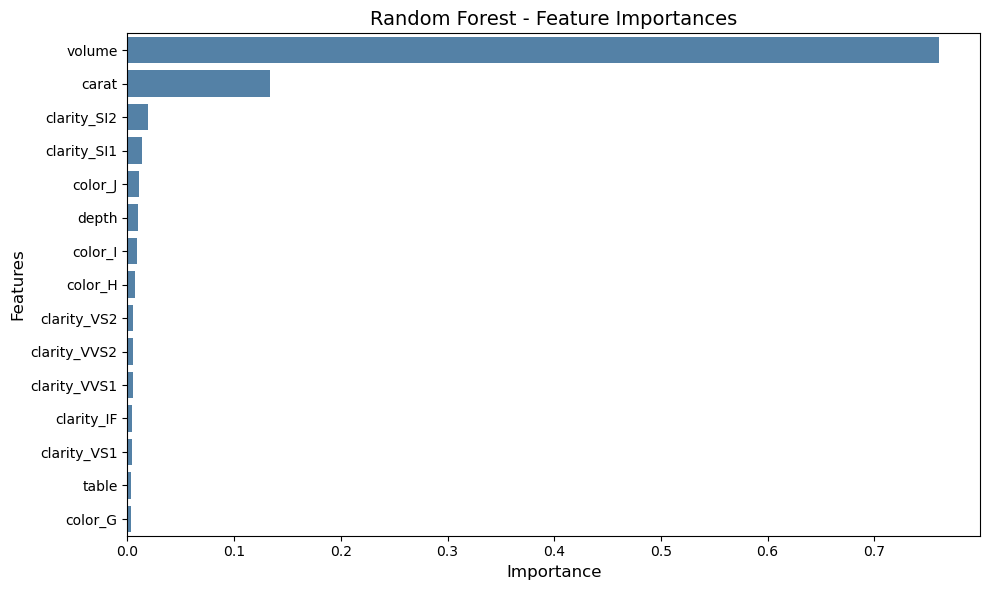

In [12]:
feature_importances = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("--- Feature Importances ---")
print(feature_importances.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance", 
    y="Feature", 
    data=feature_importances.head(15), 
    color='steelblue'
)
plt.title("Random Forest - Feature Importances", fontsize=14)
plt.xlabel("Importance", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.tight_layout()
plt.show()